# GLCMaeV9 Inference Pipeline

Load a trained `GLCMaeV9` checkpoint, run inference on welding robot data, and produce anomaly verdicts with p99 aggregation.

**V9 changes vs V8:**
- **p99 aggregation** (was p95) — captures short-duration anomalies better
- **No tail window** — only stride-based windowing (T=512, seq_len=256, stride=64 → 5 windows)
- **k_skip=1** — minimal boundary trimming
- **GlobalSeqNorm** running stats from checkpoint, used in eval mode

**Threshold calibration flow:**
- Use `threshold_calibration_welding_robot.csv` (normal + 5 anomaly types, labelled)
- Plot score distribution per sensor × per anomaly type
- Select threshold → save to `THRESHOLD_CONFIG` → `threshold_config.json`
- Final evaluation on `test_welding_robot.csv`

**Pipeline:**
1. Load trained model checkpoint
2. Load threshold calibration CSV → preprocess into file-windows
3. Load test CSV + test_labels → preprocess into file-windows
4. Score threshold_calibration + test sets with `Reconf9LocalPreResult`
5. Plot score distributions → select threshold
6. Apply threshold to test set → evaluate per-type F1 / AUROC
7. Per-sensor heatmap analysis
8. Summary report

In [1]:
# %% Imports
import sys
import csv
import json
from pathlib import Path
from collections import defaultdict

import numpy as np
import torch
import matplotlib.pyplot as plt
import pandas as pd

# Add project root to path
project_root = Path.cwd().parent.parent.resolve()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from app.anomaly_detection.models import GLCMaeV9, ReconstructionModels
from app.anomaly_detection.inference.recon_v9.local import (
    Reconf9LocalPreResult,
    Reconf9LocalThresholdCreator,
    Reconf9LocalApplier,
)

print("All imports OK")
print(f"PyTorch {torch.__version__}, CUDA available: {torch.cuda.is_available()}")

All imports OK
PyTorch 2.12.0+cu130, CUDA available: True


## 1. Load Trained Model Checkpoint

Load the model state_dict + config saved by the training notebook (Training-GLCReconV9.ipynb).
Includes GlobalSeqNorm `running_mean`/`running_var` in state_dict.

In [2]:
CHECKPOINT_PATH = project_root / "checkpoints" / "glc_mae_v9" / "best_glc_mae_v9.pt"

if not CHECKPOINT_PATH.exists():
    print(f"Checkpoint not found: {CHECKPOINT_PATH}")
    print("Run Training-GLCReconV9.ipynb first to train and save a model.")
else:
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    checkpoint = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=False)

    metadata = checkpoint["metadata"]
    config_dict = checkpoint["config"]
    state_dict = checkpoint["model_state_dict"]
    robot_codebook = checkpoint.get("robot_to_idx", {})
    program_codebook = checkpoint.get("program_to_idx", {})

    model = GLCMaeV9(**config_dict)
    model.load_state_dict(state_dict)
    model.to(device).eval()

    print(f"Model restored to {device}: {model.name}")
    print(f"  Params:            {sum(p.numel() for p in model.parameters()):,}")
    print(f"  num_sensors:       {model.num_sensors}")
    print(f"  seq_len:           {model.seq_len}")
    print(f"  normalizer:        {metadata.get('normalizer', 'N/A')}")
    print(f"  GlobalSeqNorm running_mean: {model.seq_norm.bn.running_mean}")
    print(f"  GlobalSeqNorm running_var:  {model.seq_norm.bn.running_var[:3]}... (first 3)")
    print(f"  Checkpoint epoch:  {checkpoint.get('epoch', 'N/A')}")
    print(f"  Best val_loss:     {checkpoint.get('val_loss', 'N/A'):.4f}")

Model restored to cuda: GLCMaeV9
  Params:            966,743
  num_sensors:       3
  seq_len:           256
  normalizer:        log+global_seq_norm
  GlobalSeqNorm running_mean: tensor([5.2280, 3.5733, 2.6878], device='cuda:0')
  GlobalSeqNorm running_var:  tensor([1.1286, 0.0085, 0.0496], device='cuda:0')... (first 3)
  Checkpoint epoch:  68
  Best val_loss:     0.1431


/home/trietlm/TED-Hackathon-Agent/backend/app/anomaly_detection/layers/attention.py:97: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


## 2. Load Data Files

Load threshold_calibration (for threshold selection) and test (for evaluation) data.
Both generated by `Sprint20-Generate-Data.ipynb`.

In [3]:
DATA_DIR = project_root / "data" / "generated_sprint20"
CALIB_CSV = DATA_DIR / "threshold_calibration_welding_robot.csv"
CALIB_LABELS_CSV = DATA_DIR / "threshold_calibration_labels.csv"
TEST_CSV = DATA_DIR / "test_welding_robot.csv"
TEST_LABELS_CSV = DATA_DIR / "test_labels.csv"

SENSOR_COLS = ["wire_feed_speed_mm_min", "wire_temperature_c", "welding_current_a"]
SEQ_LEN = model.seq_len
STRIDE = 64  # no tail window

def load_csv_to_file_records(csv_path):
    """Load CSV -> group by cycle_id -> build file_records (full signal)."""
    print(f"Reading {csv_path}...")
    df = pd.read_csv(csv_path)
    print(f"  Rows: {len(df):,}, cycle_ids: {df['cycle_id'].nunique()}")
    records = []
    for cid, group in df.groupby("cycle_id"):
        group = group.sort_values("serial_number")
        file_arr = np.array([group[col].values for col in SENSOR_COLS], dtype=np.float32)
        records.append({
            "cycle_id": cid,
            "window": file_arr,
            "robot_code": str(group["robot_code"].iloc[0]),
            "program_number": int(group["program_number"].iloc[0]),
            "anomaly_type": str(group["anomaly_type"].iloc[0]),
        })
    return records

print("=" * 50)
print("LOADING DATA")
print("=" * 50)

calib_records = load_csv_to_file_records(CALIB_CSV)
test_records = load_csv_to_file_records(TEST_CSV)

# Extend codebooks for any unseen codes
for r in calib_records + test_records:
    rc, pn = str(r["robot_code"]), str(r["program_number"])
    if rc not in robot_codebook:
        robot_codebook[rc] = len(robot_codebook)
    if pn not in program_codebook:
        program_codebook[pn] = len(program_codebook)

# Load labels
calib_labels = pd.read_csv(CALIB_LABELS_CSV)
test_labels = pd.read_csv(TEST_LABELS_CSV)

calib_norm = sum(1 for r in calib_records if r["anomaly_type"] == "normal")
calib_anom = sum(1 for r in calib_records if r["anomaly_type"] != "normal")
test_norm  = sum(1 for r in test_records if r["anomaly_type"] == "normal")
test_anom  = sum(1 for r in test_records if r["anomaly_type"] != "normal")
print(f"\nThreshold Calibration: {len(calib_records)} files ({calib_norm} normal, {calib_anom} anomaly)")
print(f"Test:                  {len(test_records)} files ({test_norm} normal, {test_anom} anomaly)")

LOADING DATA
Reading /home/trietlm/TED-Hackathon-Agent/data/generated_sprint20/threshold_calibration_welding_robot.csv...


  Rows: 4,096,000, cycle_ids: 8000
Reading /home/trietlm/TED-Hackathon-Agent/data/generated_sprint20/test_welding_robot.csv...
  Rows: 4,096,000, cycle_ids: 8000

Threshold Calibration: 8000 files (5590 normal, 2410 anomaly)
Test:                  8000 files (4022 normal, 3978 anomaly)


## 3. Build Macro-Window Records

V9: No tail window. Only `range(0, T - seq_len + 1, stride)`.
For T=512, seq_len=256, stride=64: exactly 5 windows.

In [4]:
def build_pre_result_records(records_list, seq_len=None, stride=STRIDE):
    """Convert file_records -> pre_result_records for score_batch().

    V9: NO tail window. Only stride-based windows.
    """
    if seq_len is None:
        seq_len = model.seq_len
    pre_records = []
    for rec in records_list:
        file_arr = rec["window"]  # [C, T]
        C, T = file_arr.shape
        rc = rec["robot_code"]
        pn = str(rec["program_number"])

        windows = []
        serials = []
        if T >= seq_len:
            # V9: no tail window
            for start in range(0, T - seq_len + 1, stride):
                windows.append(file_arr[:, start:start + seq_len])
                serials.append(start)
        else:
            # Short file: pad to seq_len
            pad = np.zeros((C, seq_len - T), dtype=np.float32)
            windows.append(np.hstack([file_arr, pad]))
            serials.append(0)

        pre_records.append({
            "robot_code": rc,
            "program_number": pn,
            "start_time": str(rec.get("cycle_id", 0)),
            "windows": np.stack(windows, axis=0).astype(np.float32),
            "serials": np.array(serials, dtype=np.int64),
            "anomaly_type": rec["anomaly_type"],
        })
    return pre_records

calib_pre = build_pre_result_records(calib_records)
test_pre = build_pre_result_records(test_records)
print(f"Calibration records: {len(calib_pre)} files")
print(f"  Example windows shape: {calib_pre[0]['windows'].shape}")
print(f"  Example serials:       {calib_pre[0]['serials']}")
print(f"Test records: {len(test_pre)} files")

Calibration records: 8000 files
  Example windows shape: (5, 3, 256)
  Example serials:       [  0  64 128 192 256]
Test records: 8000 files


## 4. Score Files with Reconf9LocalPreResult

Uses p99 aggregation with k_skip=1.
GlobalSeqNorm stats from checkpoint are used in eval mode.

In [5]:
engine = Reconf9LocalPreResult(
    model_version=ReconstructionModels.GLC_MAE_V9,
    metadata=metadata,
    state_dict=state_dict,
    quantile=0.99,
    k_skip=1,
    device=str(device),
    robot_codebook=robot_codebook,
    program_codebook=program_codebook,
)

print("Scoring threshold calibration set...")
calib_scores = engine.score_batch(calib_pre)
print(f"  {len(calib_scores)} files scored")

print("Scoring test set...")
test_scores = engine.score_batch(test_pre)
print(f"  {len(test_scores)} files scored")

# Show sample score keys
print(f"\nSample calibration scores[0] keys:")
for k, v in calib_scores[0].items():
    if isinstance(v, (float, int, str)):
        print(f"  {k}: {v}")
    elif isinstance(v, list) and len(v) < 10:
        print(f"  {k}: {v[:3]}... (len={len(v)})")

Scoring threshold calibration set...


/home/trietlm/TED-Hackathon-Agent/backend/app/anomaly_detection/layers/attention.py:97: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


  8000 files scored
Scoring test set...
  8000 files scored

Sample calibration scores[0] keys:
  robot_code: 3
  program_number: 12
  start_time: 1
  p99_score: 0.31793445348739624
  p99_score_rampup: 0.0
  p99_score_active: 8.4350004196167
  valid_start_idx: 64
  valid_end_idx: 448
  p99_score_wire_feed_speed: 0.03191196173429489
  p99_score_wire_temperature: 0.3180752098560333
  p99_score_welding_current: 0.220109760761261


## 5. Threshold Calibration

Plot score distribution per sensor × per anomaly type using calibration data.
Select threshold manually (or use MAD-based automated threshold).

Calibration data breakdown:
  Normal:   5590 files
  arc_blow       : 489 files
  cable_wear     : 457 files
  flatline       : 497 files
  spike          : 485 files
  thermal_drift  : 482 files


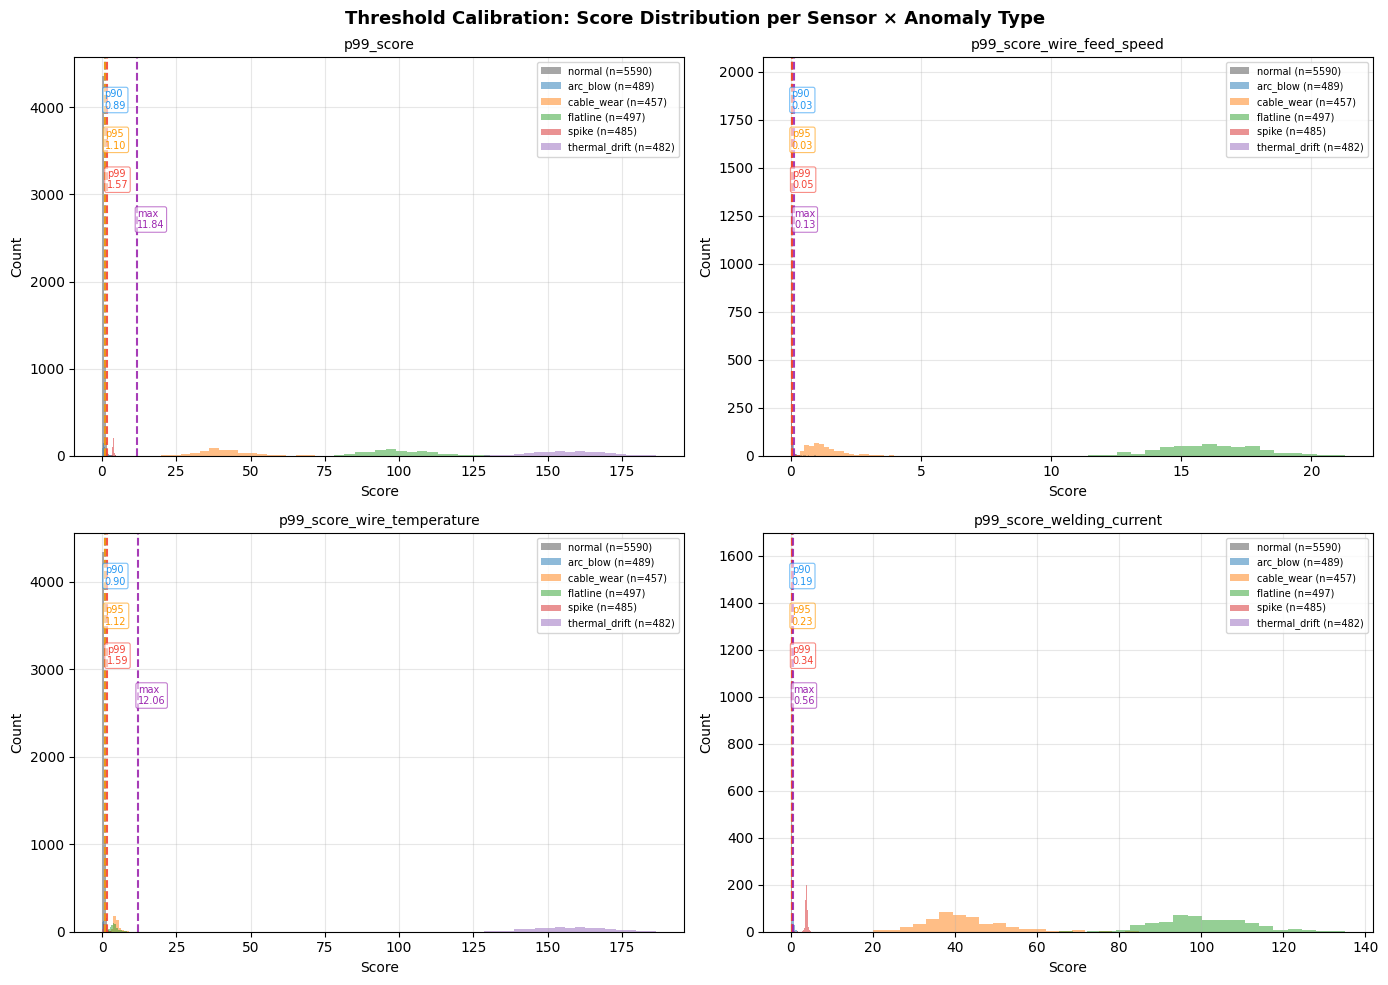

In [6]:
# Separate into normal and anomaly groups
calib_norm_scores = [s for s, rec in zip(calib_scores, calib_pre) if rec["anomaly_type"] == "normal"]
all_anomaly_types = sorted(set(rec["anomaly_type"] for rec in calib_pre if rec["anomaly_type"] != "normal"))

calib_by_type = {}
for at in all_anomaly_types:
    calib_by_type[at] = [s for s, rec in zip(calib_scores, calib_pre) if rec["anomaly_type"] == at]

print("Calibration data breakdown:")
print(f"  Normal:   {len(calib_norm_scores)} files")
for at, scores in calib_by_type.items():
    print(f"  {at:15s}: {len(scores)} files")

# Percentiles to mark on normal distribution
VLINE_QUANTILES = [90, 95, 99, 100]
VLINE_COLORS    = ["#2196F3", "#FF9800", "#F44336", "#9C27B0"]  # blue, orange, red, purple

score_keys = ["p99_score", "p99_score_wire_feed_speed", "p99_score_wire_temperature", "p99_score_welding_current"]
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for idx, sk in enumerate(score_keys):
    ax = axes[idx]
    norm_vals = np.array([s[sk] for s in calib_norm_scores])

    # Histogram: normal + each anomaly type
    ax.hist(norm_vals, bins=20, alpha=0.7, color="gray", label=f"normal (n={len(norm_vals)})")
    for at in all_anomaly_types:
        vals = [s[sk] for s in calib_by_type[at]]
        if vals:
            ax.hist(vals, bins=20, alpha=0.5, label=f"{at} (n={len(vals)})")

    # Vertical lines at normal percentiles (normal-only)
    for pct, color in zip(VLINE_QUANTILES, VLINE_COLORS):
        v = float(np.percentile(norm_vals, pct)) if pct < 100 else float(norm_vals.max())
        label_str = f"p{pct}" if pct < 100 else "max"
        ax.axvline(v, color=color, linewidth=1.5, linestyle="--", alpha=0.9)
        # Stagger labels vertically to avoid overlap
        y_frac = 0.92 - VLINE_QUANTILES.index(pct) * 0.10
        ax.text(
            v, ax.get_ylim()[1] * y_frac,
            f"{label_str}\n{v:.2f}",
            color=color, fontsize=7, ha="left", va="top",
            bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.6, ec=color, lw=0.8),
        )

    ax.set_title(sk, fontsize=10)
    ax.set_xlabel("Score")
    ax.set_ylabel("Count")
    ax.legend(fontsize=7)
    ax.grid(True, alpha=0.3)

plt.suptitle("Threshold Calibration: Score Distribution per Sensor × Anomaly Type", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()


## 6. Set Per-Sensor Thresholds Manually

Read the calibration plots above (p90/p95/p99 vlines on the normal distribution).
Pick a threshold per sensor that sits above the normal tail — typically just above p99.
No automated ThresholdCreator: manual choice is clearer and avoids MAD calibration skew.

In [7]:
# ── Set per-sensor thresholds from calibration plots ────────────────────────
# Read the p90/p95/p99 vlines on the normal histogram and pick a value
# just above the normal tail for each sensor.

SENSOR_THRESHOLDS = {
    "p99_score_wire_feed_speed":   0.13,   # ← adjust from calibration plot
    "p99_score_wire_temperature":  12.06,  # ← adjust from calibration plot
    "p99_score_welding_current":   0.56,  # ← adjust from calibration plot
}

# Sanity-check: what % of calibration NORMAL files would be flagged per sensor
print("Calibration normal — files exceeding each threshold (target < 2%):")
any_triggered = np.zeros(len(calib_norm_scores), dtype=bool)
for sk, thresh in SENSOR_THRESHOLDS.items():
    vals = np.array([s[sk] for s in calib_norm_scores])
    exceed_mask = vals > thresh
    any_triggered |= exceed_mask
    p99_val = float(np.percentile(vals, 99))
    print(f"  {sk:40s}  thresh={thresh:7.2f}  p99={p99_val:7.2f}  FP={exceed_mask.mean()*100:.1f}%")

print(f"\n  OR-combined FPR on calibration normal: {any_triggered.mean()*100:.1f}%")

# Save
config_path = project_root / "config" / "threshold_config_v9.json"
config_path.parent.mkdir(parents=True, exist_ok=True)
with open(config_path, "w") as f:
    json.dump(SENSOR_THRESHOLDS, f, indent=2)
print(f"\nThreshold config saved → {config_path}")


Calibration normal — files exceeding each threshold (target < 2%):
  p99_score_wire_feed_speed                 thresh=   0.13  p99=   0.05  FP=0.0%
  p99_score_wire_temperature                thresh=  12.06  p99=   1.59  FP=0.0%
  p99_score_welding_current                 thresh=   0.56  p99=   0.34  FP=0.0%

  OR-combined FPR on calibration normal: 0.0%

Threshold config saved → /home/trietlm/TED-Hackathon-Agent/config/threshold_config_v9.json


## 7. Evaluate on Test Set

Apply threshold to test set and compute per-type metrics.

In [8]:
applier = Reconf9LocalApplier(sensor_thresholds=SENSOR_THRESHOLDS, quantile=0.99)
test_results = applier.apply(test_scores)

# Evaluate per-type
anomaly_types = [rec["anomaly_type"] for rec in test_pre]
verdicts = [r["is_file_anomaly"] for r in test_results]

print("=" * 60)
print("TEST SET EVALUATION")
print("=" * 60)
print(f"{'Type':20s} {'Total':>6s} {'Flagged':>7s} {'Rate':>8s}")
print("-" * 45)
for at in sorted(set(anomaly_types)):
    indices = [i for i, t in enumerate(anomaly_types) if t == at]
    total = len(indices)
    flagged = sum(verdicts[i] for i in indices)
    rate = flagged / total * 100 if total > 0 else 0
    print(f"{at:20s} {total:6d} {flagged:7d} {rate:7.1f}%")

total_norm = sum(1 for t in anomaly_types if t == "normal")
total_anom = len(anomaly_types) - total_norm
norm_flagged = sum(verdicts[i] for i, t in enumerate(anomaly_types) if t == "normal")
anom_flagged = sum(verdicts[i] for i, t in enumerate(anomaly_types) if t != "normal")
fpr = norm_flagged / total_norm * 100 if total_norm > 0 else 0
tpr = anom_flagged / total_anom * 100 if total_anom > 0 else 0
print("-" * 45)
print(f"{'Normal':20s} {total_norm:6d} {norm_flagged:7d} {fpr:7.1f}% (FPR)")
print(f"{'Anomaly (all)':20s} {total_anom:6d} {anom_flagged:7d} {tpr:7.1f}% (TPR)")
print("=" * 60)

# Show which sensors triggered most FPs on normal
print("\nFalse-positive trigger breakdown (normal files):")
norm_results = [r for r, at in zip(test_results, anomaly_types) if at == "normal"]
for sk in SENSOR_THRESHOLDS:
    fp_count = sum(1 for r in norm_results if sk in r.get("triggered_by", []))
    print(f"  {sk:40s}: {fp_count:5d} / {total_norm} ({fp_count/total_norm*100:.1f}%)")


TEST SET EVALUATION
Type                  Total Flagged     Rate
---------------------------------------------
arc_blow                835     369    44.2%
cable_wear              744     744   100.0%
flatline                792     792   100.0%
normal                 4022       2     0.0%
spike                   829     829   100.0%
thermal_drift           778     778   100.0%
---------------------------------------------
Normal                 4022       2     0.0% (FPR)
Anomaly (all)          3978    3512    88.3% (TPR)

False-positive trigger breakdown (normal files):
  p99_score_wire_feed_speed               :     1 / 4022 (0.0%)
  p99_score_wire_temperature              :     0 / 4022 (0.0%)
  p99_score_welding_current               :     2 / 4022 (0.0%)


## 8. Summary Report

In [9]:
print("=" * 60)
print("GLCMaeV9 INFERENCE SUMMARY")
print("=" * 60)
print(f"Model:              GLCMaeV9 ({model.name})")
print(f"Normalizer:         log+global_seq_norm")
print(f"Aggregation:        p99 (quantile=0.99)")
print(f"Tail window:        NO (removed in V9)")
print(f"Stride:             {STRIDE}")
print(f"k_skip:             {engine.k_skip}")
print(f"Seq len:            {SEQ_LEN}")
print()
print(f"Threshold source:   threshold_calibration_welding_robot.csv "
      f"({len(calib_records)} files)")
print(f"Test data:          test_welding_robot.csv ({len(test_records)} files)")
print()
print("Per-sensor thresholds (manual):")
for sk, thresh in SENSOR_THRESHOLDS.items():
    print(f"  {sk:40s}: {thresh:.2f}")
print()
print(f"Normal FPR:         {fpr:.1f}% ({norm_flagged}/{total_norm})")
print(f"Anomaly TPR:        {tpr:.1f}% ({anom_flagged}/{total_anom})")
print()
print("Per-type detection rates:")
for at in sorted(set(anomaly_types)):
    indices = [i for i, t in enumerate(anomaly_types) if t == at]
    total = len(indices)
    flagged = sum(verdicts[i] for i in indices)
    rate = flagged / total * 100 if total > 0 else 0
    print(f"  {at:20s}: {flagged:3d}/{total:<3d} ({rate:5.1f}%)")
print("=" * 60)
print("GlobalSeqNorm running stats accumulated during training,")
print("loaded from checkpoint, frozen in eval mode.")
print(f"  running_mean: {model.seq_norm.bn.running_mean}")
print(f"  running_var:  {model.seq_norm.bn.running_var[:3]}...")


GLCMaeV9 INFERENCE SUMMARY
Model:              GLCMaeV9 (GLCMaeV9)
Normalizer:         log+global_seq_norm
Aggregation:        p99 (quantile=0.99)
Tail window:        NO (removed in V9)
Stride:             64
k_skip:             1
Seq len:            256

Threshold source:   threshold_calibration_welding_robot.csv (8000 files)
Test data:          test_welding_robot.csv (8000 files)

Per-sensor thresholds (manual):
  p99_score_wire_feed_speed               : 0.13
  p99_score_wire_temperature              : 12.06
  p99_score_welding_current               : 0.56

Normal FPR:         0.0% (2/4022)
Anomaly TPR:        88.3% (3512/3978)

Per-type detection rates:
  arc_blow            : 369/835 ( 44.2%)
  cable_wear          : 744/744 (100.0%)
  flatline            : 792/792 (100.0%)
  normal              :   2/4022 (  0.0%)
  spike               : 829/829 (100.0%)
  thermal_drift       : 778/778 (100.0%)
GlobalSeqNorm running stats accumulated during training,
loaded from checkpoint, frozen